# Урок 10. Где находится точка, когда поворачивается камера?

[Программа курса](../../README_ru.md)

На столе стоит проволочный треугольник. Камера едет вправо, и треугольник оказывается слева от неё. У проволоки не изменилось ни длины, ни положения на столе. Изменилось место, от которого отсчитывается «вправо». Перед тем как рисовать пиксели, разберёмся с этим отсчётом.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)

## 1. Треугольник в двух окнах

Оба рисунка показывают вид сверху. По горизонтали идёт $x$, по вертикали — глубина $z$. Третья координата, $y$, остаётся в расчёте. Справа начало сетки всегда находится в камере. Оранжевая вершина подвижна, две другие закреплены на общей рамке. «Точка x» сдвигает только вершину и меняет форму. «Объект x» переносит всю рамку и сохраняет её форму. «Камера x» переносит начало отсчёта. «Поворот камеры» разворачивает её оси. Короткая зелёная линия показывает, куда камера смотрит.

В начальном положении справа получается $(1,1,4)$. Теперь пусть «Объект x» и «Камера x» оба увеличатся с 1 до 2. Слева рамка и камера вместе проедут метр. Справа все три вершины останутся на тех же местах. Так выглядит опыт, в котором меняется мир, а кадр останется прежним.

In [2]:
display(demos.geometry_lab(10, "ru"))

## 2. Что можно узнать, приложив к точке три линейки

Вместе с камерой закрепим на маленьком штативе три линейки под прямыми углами. Их нулевые отметки совпадают в центре камеры. На первой написано «вправо», на второй «вниз», на третьей «вперёд». Одного начала мало. Два штатива могут стоять ножками в одном месте, но смотреть в разные стороны. Тогда подписи у одной и той же вершины будут разными. Начало вместе с выбранными направлениями и единицей длины задаёт **систему координат**.

На левом рисунке зелёная стрелка лежит в плоскости стола. По ней мы идём в глубину. Ось вниз уходит из этого рисунка. Поэтому по одному виду сверху нельзя отличить вершины $(1,1,4)$ и $(1,3,4)$ в координатах камеры. Каждая оставит метку в том же месте на бумаге, хотя между ними два метра по вертикали. Чтобы перенести точку из системы в систему, мы сохраняем все три числа. Две координаты на рисунке нужны для наблюдения за опытом.

Надпись «метр вправо от камеры» имеет знак. Если вершина оказалась слева, линейку не приходится разворачивать: отсчёт продолжается через ноль в отрицательную сторону. При отрицательной глубине вершина уже позади камеры. Длина провода от этого отрицательной не станет. Знак относится к конкретному направлению; расстояние между двумя физическими точками учитывает сразу все направления и всегда неотрицательно. На неподвижном столе удобно сначала отделить эти две задачи.

## 3. Три числа и три начала отсчёта

В пределах сцены считаем длины в метрах. Оси камеры направлены вправо ($x$), вниз ($y$) и вперёд ($z$). У такого выбора есть удобство: увеличение $y$ позднее будет двигать пиксель вниз по изображению. Тройка $(1,1,4)$ отсчитывает 1 м вправо, 1 м вниз и 4 м вперёд от выбранного начала. Отрицательное $x$ означает столько же метров влево.

Сначала выбранная вершина имеет координаты $p=(1,1,4)$ в системе самой рамки. Начало рамки стоит в точке мира $O=(1,0,0)$. Оси пока параллельны. Положение вершины в мире получается сложением по местам:

$$
P=O+p=(1+1,\;0+1,\;0+4)=(2,1,4).
$$

Ещё одно начало — центр камеры $C=(1,0,0)$ в мире. От него к вершине идёт **смещение** $d$. У смещения есть длина и направление. Оно получается вычитанием начальной точки из конечной:

$$
d=P-C=(2-1,\;1-0,\;4-0)=(1,1,4).
$$

Если камера доедет до $C=(2,0,0)$, по первому месту выйдет $2-2=0$. Вершина прямо впереди по горизонтали, хотя её мировое $x$ всё ещё равно 2. Общий перенос всех точек сохраняет любое смещение между ними: одинаковая прибавка сокращается при вычитании.

In [3]:
p = np.array([1., 1., 4.])
O = np.array([1., 0., 0.])
C = np.array([1., 0., 0.])
P = O + p
print("P =", P, "   P-C =", P - C)
assert np.array_equal((P + [1, 0, 0]) - (C + [1, 0, 0]), P - C)

P = [2. 1. 4.]    P-C = [1. 1. 4.]


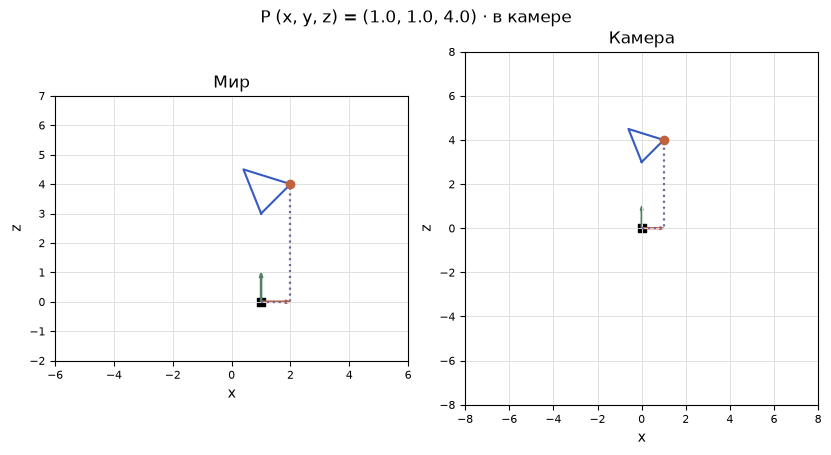

In [4]:
fig = demos.frame_figure("ru")
plt.show()

## 4. Один провод и несколько переездов

Возьмём не всю рамку, а отрезок от вершины $U=(1,0,3)$ до оранжевой вершины $P=(2,1,4)$ в мире. Стоя в $U$, до второй вершины нужно пройти метр вправо, метр вниз и метр вперёд. Стрелка $P-U=(1,1,1)$ описывает **ребро**. У вершины есть адрес, у ребра — разность двух адресов. Если рамку переставить вправо на метр, её концы окажутся в $(2,0,3)$ и $(3,1,4)$. Стрелка между ними снова получится $(1,1,1)$.

Длину провода можно проверить без поворота камеры. В плоскости стола его проекция проходит один метр вправо и один вперёд. Квадрат длины этой проекции равен $1^2+1^2=2$ м² по теореме Пифагора. Добавилась ещё высота в один метр. Квадрат пространственной длины равен $2+1^2=3$ м², сама длина равна $\sqrt{3}\approx1.732$ м. У камеры может измениться изображение обоих концов. Если в координатах камеры длина именно этого пространственного ребра стала иной, значит, в расчёт попало растяжение или перепутались единицы.

| Изменение от исходного положения | $P$ в мире, м | $P-C$ в мире, м | Что происходит с ребром |
|---|---|---|---|
| Камера и объект на $x=1$ | $(2,1,4)$ | $(1,1,4)$ | длина $\sqrt{3}$ м |
| Только рамка на $x=2$ | $(3,1,4)$ | $(2,1,4)$ | оба конца ушли вправо |
| Только камера на $x=2$ | $(2,1,4)$ | $(0,1,4)$ | концы остались на столе |
| Обе на $x=2$ | $(3,1,4)$ | $(1,1,4)$ | прежний вид из камеры |

В таблице оси камеры всё время параллельны мировым. Каждая строка начинается с одного и того же исходного положения. Интересно сравнить последнюю с первой. Для воспроизведения картинки нельзя по одному измерению $P-C$ определить, кто именно двигался. Зато по мировым координатам из соседнего столбца сразу видно, что эксперимент был разным. Позднее, когда камеры и сцена будут восстанавливаться по фотографиям, такой общий перенос станет одним из способов поменять описание, сохранив все изображения.

In [5]:
U = O + np.array([0., 0., 3.])
for shift_object, shift_camera in [(0,0), (1,0), (0,1), (1,1)]:
    shift = np.array([shift_object, 0., 0.])
    center = C + [shift_camera, 0., 0.]
    tip, base = P + shift, U + shift
    print(f"Oₓ={O[0]+shift_object:.0f}, Cₓ={center[0]:.0f}:",
          tip-center, f"  |P−U|={np.linalg.norm(tip-base):.3f} m")

Oₓ=1, Cₓ=1: [1. 1. 4.]   |P−U|=1.732 m
Oₓ=2, Cₓ=1: [2. 1. 4.]   |P−U|=1.732 m
Oₓ=1, Cₓ=2: [0. 1. 4.]   |P−U|=1.732 m
Oₓ=2, Cₓ=2: [1. 1. 4.]   |P−U|=1.732 m


## 5. Как увидеть одно направление из другого

Оси мира неподвижны. Камера повернулась вокруг своей вертикальной оси на $30^\circ$ вправо. Её единичные направления в координатах мира теперь такие:

$$
r=(0.866,0,-0.5),\quad b=(0,1,0),\quad f=(0.5,0,0.866).
$$

Буквы обозначают правую ось, ось вниз и ось вперёд. «Единичное» означает длину 1: для $f$ сумма квадратов почти равна $0.5^2+0.866^2=1$. Здесь и дальше 0.866 округлено. Длина исходного направления сохраняется при повороте. Числа 0.5 и 0.866 — синус и косинус угла: поперечная и продольная доли единичной стрелки, отклонённой от оси вперёд.

Сколько в $d=(1,1,4)$ движения вдоль новой правой оси? Один метр по мировому $x$ даёт $0.866$ м, метр по мировому $y$ даёт ноль, четыре метра по мировому $z$ дают $4\cdot(-0.5)=-2$ м. В сумме $0.866+0-2=-1.134$ м. Такое сложение попарных произведений называется **скалярным произведением**. Для единичной оси оно измеряет подписанную длину вдоль неё.

Для нижней оси получаем $0\cdot1+1\cdot1+0\cdot4=1$. Для передней — $0.5\cdot1+0\cdot1+0.866\cdot4=3.964$. После поворота вершина слева, ниже и всё ещё впереди. На виде сверху это ровно пересечение $x=-1.134$ и $z=3.964$. Провод, камера и длина смещения остались вполне материальными, поменялись только три линейки.

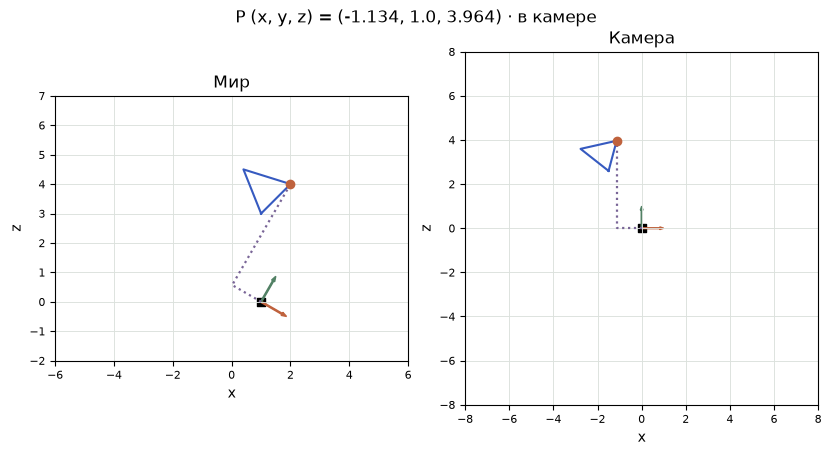

In [6]:
fig = demos.frame_figure("ru", yaw=30)
plt.show()

## 6. Разложение стрелки, которое можно собрать обратно

Фиолетовая ломаная на рисунке идёт от камеры к вершине в два хода по столу. Её первый участок параллелен правой оси камеры, второй — передней. При повороте на $30^\circ$ первый идёт **против** оранжевой стрелки. Раньше, при нулевом угле, этот участок шёл вправо. Поворот зелёной оси прошёл через направление на вершину, и знак у поперечного отсчёта успел смениться. Суммарная стрелка от камеры к вершине в мире за всё это время не повернулась ни на градус.

Можно проверить смысл числа $-1.134$ м в обратную сторону. В мировых координатах горизонтальный участок вдоль правой оси даёт примерно $-1.134(0.866,0,-0.5)=(-0.982,0,0.567)$ м. Ход вперёд даёт $3.964(0.5,0,0.866)=(1.982,0,3.433)$ м. Добавим движение вниз $(0,1,0)$: по первому месту получаем $-0.982+1.982=1$, по второму 1, по третьему $0.567+3.433=4$. Вернулась исходная стрелка $d$. Умножение на направление сообщает, куда приходится каждый метр; знак сообщает, по стрелке идти или против.

Что произойдёт за пределами малого поворота? На графике ниже камера остаётся в $(1,0,0)$ и проходит полный оборот вокруг вертикали. У вершины меняются два числа, горизонтальное и переднее. Горизонтальное обращается в ноль, когда камера смотрит на вершину точно по горизонтали. В этот момент **глубина** максимальна и равна длине стрелки на виде сверху, $\sqrt{1^2+4^2}=\sqrt{17}$ м. До полной пространственной длины всё ещё недостаёт вертикальной составляющей. Когда глубина отрицательна, точка существует в мире и прекрасно вычисляется в системе камеры. Право попасть на фотографию будет проверяться отдельно.

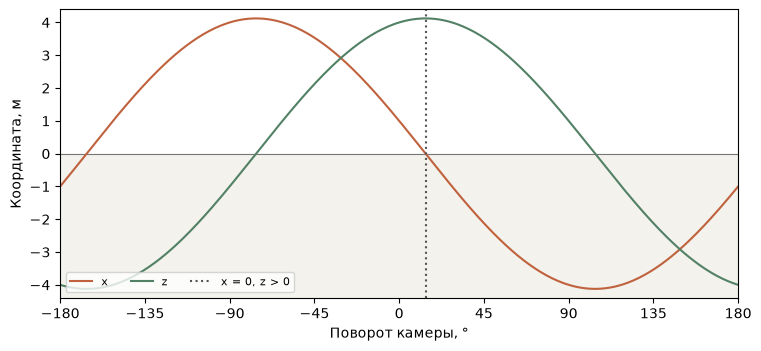

In [7]:
degrees = np.linspace(-180, 180, 361)
trace = []
for yaw in degrees:
    basis = geo.quaternion_matrix(geo.axis_angle_quaternion([0, 1, 0], yaw))
    trace.append(geo.world_to_camera(P, C, basis))
trace = np.array(trace)
np.testing.assert_allclose(trace[:,0]**2 + trace[:,2]**2, 17.)
fig, ax = plt.subplots(figsize=(7.5, 3.4), layout="constrained")
ax.axhspan(-4.4, 0, color="#f3f2ec")
ax.axhline(0, color="#777", lw=.8)
ax.plot(degrees, trace[:,0], color=demos.ORANGE, label="x")
ax.plot(degrees, trace[:,2], color=demos.GREEN, label="z")
ax.axvline(np.rad2deg(np.arctan2(1,4)), color="#555", ls=":", label="x = 0, z > 0")
ax.set(xlim=(-180,180), ylim=(-4.4,4.4), xticks=np.arange(-180,181,45),
       xlabel="Поворот камеры, °",
       ylabel="Координата, м")
ax.legend(ncol=3, loc="lower left", fontsize=8)
plt.show()

## 7. Матрица хранит три линейки

Запишем оси столбцами матрицы $B=[r\ b\ f]$. Столбец — три числа сверху вниз. Чтобы получить сразу все три скалярных произведения, нужны эти же оси **строками**. Верхний индекс $\mathsf T$ означает транспонирование: строки и столбцы меняются местами.

$$
p_c=B^{\mathsf T}(P-C)
=\begin{bmatrix}0.866&0&-0.5\\0&1&0\\0.5&0&0.866\end{bmatrix}
\begin{bmatrix}1\\1\\4\end{bmatrix}
\approx\begin{bmatrix}-1.134\\1\\3.964\end{bmatrix}.
$$

Умножение матрицы на столбец — три знакомых расчёта сверху вниз. Для обратного пути складываются три мировые стрелки: $P=C+r\,p_{c,x}+b\,p_{c,y}+f\,p_{c,z}=C+Bp_c$. Транспонирование работает как обратный поворот потому, что оси перпендикулярны и имеют длину 1. Скалярное произведение оси с собой равно 1, с соседней равно 0. Поэтому $B^{\mathsf T}B$ даёт единицы на диагонали и нули вокруг.

Когда вращается сама рамка, появляется ещё один шаг. Матрица $A$ переводит оси объекта в мир. При повороте рамки на $90^\circ$ вокруг $z$ локальная вершина $(1,1,4)$ переходит в $(-1,1,4)$. Перенос $O=(1,0,0)$ даёт мировое $(0,1,4)$. Если сначала прибавить $O$, а затем повернуть сумму, получится $(-1,2,4)$: теперь поворот унесёт и начало рамки. Общая цепочка $p_c=B^{\mathsf T}(O+Ap-C)$ читается изнутри, справа налево.

In [8]:
angle = np.deg2rad(30)
c, s = np.cos(angle), np.sin(angle)
B = np.array([[c,0,s], [0,1,0], [-s,0,c]])
pc = geo.world_to_camera(P, C, B)
print("B.T =\n", B.T, "\np_camera =", pc)
np.testing.assert_allclose(C + B @ pc, P)
np.testing.assert_allclose(B.T @ B, np.eye(3), atol=1e-14)

B.T =
 [[ 0.866  0.    -0.5  ]
 [ 0.     1.     0.   ]
 [ 0.5    0.     0.866]] 
p_camera = [-1.134   1.      3.9641]


In [9]:
A = np.array([[0,-1,0], [1,0,0], [0,0,1]])
print("O+A@p =", O + A @ p, "    A@(O+p) =", A @ (O+p))
print("world distance =", np.linalg.norm(P-C), "  camera distance =", np.linalg.norm(pc))

O+A@p = [0. 1. 4.]     A@(O+p) = [-1.  2.  4.]
world distance = 4.242640687119285   camera distance = 4.242640687119285


## 8. Камера записана как три строки и ещё один столбец

К этому месту есть два способа восстановить точку на столе. Если в памяти хранятся оси $B$ и мировое положение камеры $C$, можно прямо отложить $C+Bp_c$. А если в файле записано преобразование **из мира в камеру**, удобно его раскрыть. Обозначим $W=B^{\mathsf T}$. Распределяем умножение по разности: $W(P-C)=WP-WC$. Вторая часть одинакова для всех вершин одного кадра. Её часто хранят отдельно как $t=-WC$. Тогда в коде остаются одно умножение и одно сложение, $p_c=WP+t$.

Здесь есть коварное место. Камера стоит в $C=(1,0,0)$ м и повернута на те же $30^\circ$. Столбец $WC$ равен $(0.866,0,0.5)$, поскольку $C$ умножает первый столбец $W$ на единицу и два других на ноль. Столбец переноса равен $t=(-0.866,0,-0.5)$ м. Сравним три тройки: $C$ сообщает положение камеры в мире, $-C$ даёт направление от камеры к началу мира на старых осях, а $t$ даёт это направление на **осях камеры**. У последней тройки ненулевая глубина, хотя сама камера не передвигалась вдоль мировой оси глубины.

Подстановка самого центра камеры — хороший домашний тест для любого файла поз. В точке $P=C$ должны получить $WP+t=WC-WC=(0,0,0)$, потому что от камеры до неё самой нет смещения. Подстановка мировой точки $P=(0,0,0)$, наоборот, даёт ровно $t$. В одном кадре $t$ действительно может совпасть с $-C$, например при совпадении осей. Проверка только такого кадра пропустит неправильный код. Поворот на известный ненулевой угол выявляет ошибку сразу.

А если от штатива в файле остались только $W$ и $t$? В центре камеры координаты нулевые, значит $0=WC+t$, или $WC=-t$. Обратным поворотом переносим стрелку в мир и находим $C=-W^{\mathsf T}t$. Поменять строки и столбцы местами здесь можно потому, что три оси взаимно перпендикулярны и каждая имеет единичную длину. Если одну линейку растянуть вдвое, прямое преобразование умножит соответствующее число на два. Обратное должно будет делить на два, а простая перестановка строк со столбцами оставила бы множитель два.

Для большого массива вершин матрицу и перенос иногда склеивают в одну таблицу. К тройке координат точки приписывается единица. Первые три строки длинной таблицы содержат строку $W$ и одно число из $t$. По правилу «строка на столбец» четвёртое слагаемое умножит перенос на единицу. В последней строке стоят три нуля и единица, так что последняя координата точки сохранится. У свободного направления на четвёртом месте записывают ноль: перенос умножится на ноль и оставит длину и направление стрелки нетронутыми.

$$
\begin{bmatrix}p_c\\1\end{bmatrix}=
\begin{bmatrix}W&t\\0\;0\;0&1\end{bmatrix}
\begin{bmatrix}P\\1\end{bmatrix}.
$$

Слева и справа записаны по четыре числа, а в верхнем левом блоке — девять. Это упаковка уже проделанных операций. Одна и та же таблица годится для концов провода и для разности его концов, если различить единицу и ноль на входе. Когда камера перемещается, по отдельности пересчитаются два адреса. Если вычесть их после преобразования, столбец $t$ сократится.

In [10]:
W = B.T
t = -W @ C
T = np.eye(4)
T[:3, :3], T[:3, 3] = W, t
for name, value in [("P", np.r_[P, 1.]), ("C", np.r_[C, 1.]),
                    ("P−U", np.r_[P-U, 0.])]:
    print(name, "→", np.round(T @ value, 4))
np.testing.assert_allclose((T @ np.r_[P-U,0.])[:3], W @ (P-U))
np.testing.assert_allclose(-B @ t, C, atol=1e-14)

P → [-1.134   1.      3.9641  1.    ]
C → [0. 0. 0. 1.]
P−U → [0.366 1.    1.366 0.   ]


## 9. Что останется на рисунке

**Опыт.** Пусть камера пока смотрит прямо. Что случится с относительной координатой, если камера проедет метр вправо, а вершина проедет два?

<details>
<summary>Разбор</summary>

Новый мировой $x$ вершины равен $2+2=4$, у камеры $1+1=2$. Справа появится $4-2=2$ вместо 1. Остальные координаты останутся 1 и 4. Правая проекция выросла на разность перемещений: $2-1=1$ м.

</details>

**Ещё один ракурс.** При каком повороте начальный вектор $(1,1,4)$ окажется точно по центру по горизонтали?

<details>
<summary>Разбор</summary>

Для нового правого компонента нужно $1\cos\theta-4\sin\theta=0$. Делим на $4\cos\theta$ и получаем $\tan\theta=1/4$. Тангенс — отношение поперечного катета к продольному. Обратная операция возвращает угол, примерно $14.04^\circ$. При ближайшем целом значении $14^\circ$ остаётся около $0.003$ м. Вертикальная координата всё ещё 1, поэтому это центр только по горизонтали.

</details>

## 10. Три фотографии без сенсора

**Камера смотрит мимо.** В её системе точка получила $(0,0,-4)$ м. Какой мировой точке это соответствует для исходной камеры без поворота? Как изменится ответ при развороте на $180^\circ$ на месте?

<details>
<summary>Разбор</summary>

При нулевом угле четыре метра назад ведут от камеры в $(1,0,-4)$. После разворота её передняя стрелка указывает вдоль отрицательного мирового $z$. Четыре метра против этой стрелки ведут в $(1,0,4)$. Адрес в системе камеры в обоих случаях один. Мировые адреса разные, расстояния до соответствующей точки в обоих случаях равны 4 м.
</details>

**Ошибочная поза.** Из файла пришли $W$ и $t=(0,0,0)$, хотя камера точно стояла в $(1,0,0)$ и смотрела вправо под $30^\circ$. Какой результат для самой камеры выдаст такой файл?

<details>
<summary>Разбор</summary>

Вместо нуля получится $WC=(0.866,0,0.5)$. Отсутствующий столбец должен погасить каждое из этих трёх чисел, поэтому он равен $(-0.866,0,-0.5)$ м. Знак можно проверить на точке мира в начале координат: она и правда немного позади и слева от повёрнутой камеры.
</details>

**Миллиметры и метры.** Сканер выдал вершину $(2000,1000,4000)$ в миллиметрах, а положение камеры записано в метрах. Почему вычитание первого компонента $2000-1$ не описывает смещение в этой сцене?

<details>
<summary>Разбор</summary>

У чисел разные единицы. Точка сканера в метрах равна $(2,1,4)$. Тогда $2-1=1$ м. Можно и положение камеры перевести в миллиметры: $2000-1000=1000$ мм, та же длина. Поворот безразмерен и не меняет масштаб единиц. Ошибка перевода останется и на его выходе.
</details>

В следующем уроке та же тройка дойдёт до сенсора. Поворот уже дал глубину и поперечное смещение в одной системе. Теперь можно сравнить их как две стороны треугольника и узнать, далеко ли от середины кадра окажется вершина.